# Pouso ótimo de um drone por Programação Quadrática

**Disciplina:** Introdução à Otimização (COS360 / COM361) — PESC/COPPE/UFRJ
**Professor:** Luidi Simonetti
**Autor:** Victor Souza Trambaioli

---

**Roteiro**

1. **Introdução** — o problema, o que é *jerk*, um breve histórico e aplicações atuais.
2. **Modelo matemático** — como o pouso vira um problema de otimização.
3. **Solução** — código, resultados e gráficos.
4. **Discussão** — limitações, variações e extensões.
5. **Referências**

# 1. Introdução

## 1.1 O problema

Um drone está voando a uma determinada de altura, avançando e descendo ao mesmo tempo, e precisa **pousar sobre uma plataforma** fixa

Existem infinitos caminhos entre a posição atual e a plataforma, e infinitas maneiras de percorrer cada um (mais rápido no começo, mais devagar no fim, etc.). Queremos o pouso que seja:

- **suave**: sem freadas bruscas nem "trancos", que sacodem a carga, exigem mudanças bruscas dos motores e são difíceis de seguir com precisão;
- **seguro**: tocar o chão dentro da plataforma, com folga da borda; não voar baixo longe dela; e chegar devagar perto do chão;
- **possível para o drone**: um quadricóptero só empurra para "cima" do próprio corpo. Para se mover de lado ele precisa inclinar, e os motores têm rotação mínima e máxima.

A pergunta do trabalho é:

> **Dentre todas as trajetórias que levam o drone até a plataforma respeitando essas regras, qual é a mais suave?**


## 1.2 O que é *jerk*

Para medir a suavidade, olhamos para as derivadas da posição $p(t)$ no tempo:

| Grandeza | Definição | Unidade | Intuição |
|---|---|---|---|
| Posição | $p(t)$ | m | onde o drone está |
| Velocidade | $v(t) = \dot p(t)$ | m/s | quão rápido ele se move |
| Aceleração | $a(t) = \ddot p(t)$ | m/s² | quão rápido a velocidade muda |
| **Jerk** | $j(t) = \dddot p(t)$ | m/s³ | **quão rápido a aceleração muda** |


Num drone, o jerk tem também um significado físico direto: para mudar de aceleração, o drone precisa **mudar de inclinação**. Jerk pequeno significa que ele gira devagar.

O critério usado é minimizar a **integral do quadrado do jerk** ao longo do pouso:
$$
J = \int_0^T \|j(t)\|^2 \, dt .
$$
O quadrado penaliza igualmente jerks para qualquer lado e pesa mais os jerks grandes; a integral soma essa penalização ao longo de todo o movimento.

## 1.3 Breve histórico

- **Movimento humano (anos 1980).** Hogan (1984) e Flash & Hogan (1985) mostraram que os movimentos do braço humano ao alcançar um objeto são muito bem descritos pela trajetória que minimiza a integral do jerk ao quadrado. Entre dois pontos em repouso, a solução é um polinômio de 5º grau no tempo. O "mínimo jerk" virou um critério clássico de suavidade e foi adotado em robótica.
- **Pouso guiado por otimização convexa (2007 em diante).** Açıkmeşe & Ploen (2007) formularam a guiagem do pouso propulsado em Marte como um problema de **otimização convexa**, o que garante encontrar a melhor solução de forma rápida e confiável. Técnicas dessa família foram usadas no pouso autônomo de foguetes reutilizáveis (Blackmore, 2016).
- **Quadricópteros (2011).** Mellinger & Kumar (2011) mostraram que, para um quadricóptero, basta planejar a trajetória da posição (e da orientação em torno da vertical): a inclinação e o empuxo dos motores podem ser calculados a partir dela. Eles geraram trajetórias suaves resolvendo uma **programação quadrática**, abordagem que se tornou padrão no planejamento de drones.
- **Pouso dinâmico de drones (2024).** Lo et al. (2024) propõem um sistema para pousar quadricópteros em plataformas que podem estar em movimento. No planejamento, minimizam a integral do jerk ao quadrado com restrições de segurança e de viabilidade dinâmica. **É desse trabalho que vem o critério usado aqui.**

## 1.4 Aplicações atuais

Trajetórias de mínimo jerk (ou de derivadas mais altas) e o planejamento de pouso por otimização aparecem em:

- **drones**: pouso em plataformas fixas ou móveis (navios, veículos), estações de recarga automática, entregas e inspeção;
- **foguetes reutilizáveis e sondas espaciais**: pouso de precisão guiado por otimização convexa;
- **robôs industriais e máquinas CNC**: trajetórias suaves reduzem vibração e desgaste;
- **veículos e elevadores**: o conforto dos passageiros está ligado ao jerk;
- **reabilitação e próteses**: geração de movimentos com aparência natural.

# 2. Modelo matemático

## 2.1 Modelagem do drone

O drone considerado é o **Holybro X500 V2**, um quadricóptero de pesquisa com cerca de 1,3 kg e quatro motores dispostos em X. Antes de planejar o pouso, precisamos de um modelo que diga **como o drone se move** e **o que ele precisa fazer** (inclinar, acelerar os motores) para seguir uma trajetória.

O modelo matemático desta seção segue Mellinger, D.; Kumar, V. (2011).

### Hipóteses

- O drone é um **corpo rígido** de massa $m$.
- O **yaw é travado** ($\psi = 0$): o drone não gira em torno da vertical. Para andar em $x$ ele usa o **pitch** $\theta$ (inclina para a frente ou para trás) e, para andar em $y$, o **roll** $\phi$ (inclina para os lados).
- Os motores atingem a rotação pedida instantaneamente. O tempo de resposta real é de dezenas de milissegundos, pequeno perto dos segundos que dura o pouso.
- Não há vento nem arrasto do ar.

### Passo 1 — A força de cada motor

Um motor girando a $\omega_i$ rad/s gera uma força proporcional ao quadrado da rotação, $F_i = k_F\,\omega_i^2$, na direção do eixo do motor. Os quatro motores apontam para o mesmo lado, o "teto" do drone, que chamamos de eixo $z_B$. O **empuxo total** é
$$
F = k_F\,(\omega_1^2 + \omega_2^2 + \omega_3^2 + \omega_4^2).
$$

### Passo 2 — Lei de Newton

Sobre o drone agem só duas forças: o empuxo $F$, na direção $z_B$, e o peso $mg$, para baixo. Então
$$
m\,a = F\,z_B - m g\,\hat z
\qquad\Longrightarrow\qquad
\boxed{\; t \;=\; a + g\,\hat z \;=\; \frac{F}{m}\,z_B \;}
$$
O vetor $t = (a_x,\ a_y,\ a_z + g)$ é a aceleração que os motores precisam produzir: a aceleração desejada mais a compensação da gravidade. A equação diz duas coisas:
- a **direção** de $t$ é a direção do teto do drone, ou seja, a sua **inclinação**;
- o **comprimento** de $t$ é $F/m$, a **aceleração produzida pelo empuxo**. Como a massa é fixa, ele determina o empuxo: $F = m\,\|t\|$.

Um quadricóptero, portanto, **não consegue acelerar de lado sem inclinar**. Para pairar ($a = 0$), $t = (0, 0, g)$: o drone fica nivelado e o empuxo iguala o peso.

### Passo 3 — Inclinação com yaw travado

Com $\psi = 0$, a orientação do drone é dada pelo roll $\phi$ e pelo pitch $\theta$, e o teto do drone aponta para
$$
z_B = (\sin\theta,\ -\sin\phi\cos\theta,\ \cos\phi\cos\theta).
$$
Substituindo no Passo 2, componente a componente:
$$
a_x = \frac{F}{m}\sin\theta, \qquad
a_y = -\frac{F}{m}\sin\phi\cos\theta, \qquad
a_z = \frac{F}{m}\cos\phi\cos\theta - g .
$$
Inclinar para a frente ($\theta > 0$) acelera em $+x$; inclinar de lado acelera em $y$; e a parte vertical do empuxo sustenta o peso.

![Ângulos de pitch e roll](figuras/angulos_pitch_roll.png)

*Figura: o pitch $\theta$ gira o drone em torno do eixo $y$ e inclina o teto ($z_B$, direção do empuxo) para $+x$; o roll $\phi$ gira em torno do eixo $x$ e, pela convenção do modelo, $\phi > 0$ inclina o teto para $-y$.

### Passo 4 — Da trajetória para o drone

As contas também podem ser invertidas. **Conhecida a aceleração** $a$ (que vem da trajetória), todas as grandezas físicas do drone ficam determinadas:
$$
F = m\,\|t\|, \qquad
\phi = \operatorname{atan2}(-a_y,\ a_z + g), \qquad
\theta = \arcsin\!\left(\frac{a_x}{\|t\|}\right), \qquad
\bar\omega = \sqrt{\frac{F}{4\,k_F}} ,
$$
em que $\bar\omega$ é a rotação média dos motores.

Essa propriedade, chamada de **planicidade diferencial** (Mellinger & Kumar, 2011), é o que permite **planejar só a trajetória da posição** $p(t)$: o empuxo, os ângulos e a rotação dos motores são consequências dela.


### Parâmetros do X500 V2

| Parâmetro | Valor | Origem |
|---|---|---|
| massa $m$ | 1,3269 kg | Bowerfind et al. (2025), Tabela 1 |
| rotação dos motores | 115 a 907 rad/s | Bowerfind et al. (2025), Tabela 1 |
| braço (centro até o motor) | 0,25 m | Bowerfind et al. (2025), Tabela 1 |
| coeficiente de empuxo $k_F$ | $1{,}2 \cdot 10^{-5}$ N·s²/rad² | datasheet T-Motor AIR2216 II KV920 + T1045\* |
| inclinação máxima (roll e pitch) | 30° | arbitrado |
| giro máximo | 60°/s | arbitrado |

\* O $k_F$ foi tirado do datasheet de outro modelo de motor.

Com esses números, o empuxo pode variar entre $F_{\min} = 4 k_F \omega_{\min}^2$ e $F_{\max} = 4 k_F \omega_{\max}^2$.

### Passo 5 — Limites físicos como restrições lineares

O drone tem limites: inclinação máxima, rotação mínima e máxima dos motores (logo, empuxo mínimo e máximo) e velocidade máxima de giro. Mas **ângulos, empuxo e rotação não são variáveis do problema**: eles são calculados a partir da aceleração (Passo 4). Se fossem variáveis, as relações com seno, cosseno e raiz deixariam o problema não linear.

A saída é escrever cada limite **diretamente sobre a aceleração $a$ ou o jerk $j$**, usando o vetor $t = (a_x,\ a_y,\ a_z + g)$: os ângulos são a **direção** de $t$, e o empuxo, o seu **comprimento** vezes a massa.

| Limite físico | Forma exata | Forma usada (linear) | Tipo |
|---|---|---|---|
| roll $\lvert\phi\rvert \le \phi_{\max}$ | $\lvert a_y\rvert \le \tan\phi_{\max}\,(a_z+g)$ | a mesma | exata |
| pitch $\lvert\theta\rvert \le \theta_{\max}$ | $\lvert a_x\rvert \le \tan\theta_{\max}\sqrt{a_y^2+(a_z+g)^2}$ | $\lvert a_x\rvert \le \tan\theta_{\max}\,(a_z+g)$ | conservadora |
| empuxo mínimo, $F \ge F_{\min}$ | $\|t\| \ge F_{\min}/m$ | $a_z + g \ge F_{\min}/m$ | conservadora |
| empuxo máximo, $F \le F_{\max}$ | $\|t\| \le F_{\max}/m$ | $\lvert a_x\rvert + \lvert a_y\rvert + (a_z+g) \le F_{\max}/m$ | conservadora |

- **Por que funciona.** O roll sai direto do Passo 3: $\tan\phi = -a_y/(a_z+g)$. Nas outras, usamos que $a_z + g \le \|t\| \le |a_x| + |a_y| + (a_z + g)$: trocar $\|t\|$ pelo lado que deixa a desigualdade mais exigente dá uma forma linear.
- **Conservadora** quer dizer mais exigente que a física: pode proibir algumas trajetórias que seriam possíveis, mas **nunca permite uma impossível**. Como o drone voa quase na vertical, a diferença é pequena.
- **Continua QP.** Cada $|\cdot| \le$ vira duas desigualdades lineares; o empuxo máximo, com dois módulos, vira quatro ($\pm a_x \pm a_y + (a_z + g) \le F_{\max}/m$). A forma exata do empuxo máximo seria uma bola ($\|t\| \le F_{\max}/m$), uma restrição de cone de segunda ordem, que tiraria o problema da classe QP.
- Depois de resolver, os ângulos, o empuxo e a rotação dos motores são recuperados com as fórmulas exatas do Passo 4, para conferir que ficaram dentro dos limites.

In [ ]:
# ----------------------------------------------------------------------
# O modelo do drone em código — Configuração
# ----------------------------------------------------------------------
# Importa as bibliotecas e define as cores fixas usadas em todos os gráficos.

import numpy as np
import matplotlib.pyplot as plt
import cvxpy as cp

# Cores fixas por eixo: X, Y e Z têm sempre a mesma cor em todos os gráficos.
COR = {"x": "#2a78d6", "y": "#eb6834", "z": "#1baf7a"}
COR_LIMITE = "#8a8a85"      # linhas tracejadas de limites
COR_PLATAFORMA = "#bdbcb5"  # plataforma de pouso
EIXOS = ["x", "y", "z"]

plt.rcParams.update({
    "figure.facecolor": "white",    # fundo branco (no tema escuro do VS Code, o fundo transparente fica preto)
    "savefig.facecolor": "white",
    "axes.facecolor": "white",
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "lines.linewidth": 2,
})

In [2]:
# ----------------------------------------------------------------------
# Parâmetros do X500 V2
# ----------------------------------------------------------------------
# Define os parâmetros da tabela acima e calcula os limites de empuxo e a rotação necessária para
# pairar.

GRAV = 9.81                       # [m/s²] aceleração da gravidade
M_DRONE = 1.3269                  # [kg] massa
K_F = 1.2e-5                      # [N·s²/rad²] coeficiente de empuxo de cada motor
OMEGA_MIN, OMEGA_MAX = 115, 907   # [rad/s] faixa de rotação dos motores
BRACO = 0.25                      # [m] distância do centro até cada motor
ANG_MAX = np.radians(30)          # inclinação máxima em roll e em pitch
GIRO_MAX = np.radians(60)         # [rad/s] velocidade máxima de giro em roll e em pitch

EMPUXO_MIN = 4 * K_F * OMEGA_MIN**2   # [N] todos os motores na rotação mínima
EMPUXO_MAX = 4 * K_F * OMEGA_MAX**2   # [N] todos os motores na rotação máxima
OMEGA_PAIRADO = np.sqrt(M_DRONE * GRAV / (4 * K_F))



Peso: 13.02 N
Empuxo: de 0.63 N a 39.5 N (até 3.0 vezes o peso)
Rotação para pairar: 521 rad/s (4973 rpm), dentro da faixa 115–907 rad/s


In [3]:
# ----------------------------------------------------------------------
# Da aceleração para o drone
# ----------------------------------------------------------------------
# Implementa o Passo 4: dada a aceleração (um vetor ou uma sequência de vetores no tempo), calcula
# empuxo, roll, pitch e rotação média dos motores. A função `rotacao` monta a orientação do drone
# a partir dos ângulos; as colunas da matriz são os eixos x_B, y_B e z_B do drone.

def grandezas_fisicas(acel):
    # acel: array com 3 linhas (a_x, a_y, a_z); pode ter uma coluna por instante.
    acel = np.asarray(acel, dtype=float).reshape(3, -1)
    t_vet = acel + np.array([[0.0], [0.0], [GRAV]])       # t = a + g·ẑ
    norma = np.linalg.norm(t_vet, axis=0)
    empuxo = M_DRONE * norma                              # F = m‖t‖
    phi = np.arctan2(-acel[1], acel[2] + GRAV)            # roll
    theta = np.arcsin(acel[0] / norma)                    # pitch
    omega = np.sqrt(empuxo / (4 * K_F))                   # rotação média dos motores
    return {"empuxo": empuxo, "phi": phi, "theta": theta, "omega": omega}


def rotacao(phi, theta):
    # Orientação do drone com yaw = 0: R = Rx(φ) Ry(θ). Colunas: x_B, y_B, z_B no referencial do mundo.
    cf, sf, ct, st = np.cos(phi), np.sin(phi), np.cos(theta), np.sin(theta)
    Rx = np.array([[1, 0, 0], [0, cf, -sf], [0, sf, cf]])
    Ry = np.array([[ct, 0, st], [0, 1, 0], [-st, 0, ct]])
    return Rx @ Ry




In [4]:
# ----------------------------------------------------------------------
# Limites físicos como restrições
# ----------------------------------------------------------------------
# A função `restricoes_fisicas` escreve as cinco restrições lineares do Passo 6 para quaisquer
# variáveis de aceleração e jerk; ela é aplicada às variáveis do problema na seção 2.2. Abaixo, o
# que esses limites significam em termos de aceleração.

def restricoes_fisicas(acel, jerk):
    # Restrições lineares do Passo 6, em todos os instantes. Devolve um dicionário de grupos nomeados.
    # Cada |u| ≤ c é escrito como o par u ≤ c e -u ≤ c (forma que o solver OSQP trata melhor).
    a_x, a_y = acel[0, :], acel[1, :]
    t_z = acel[2, :] + GRAV                                   # componente vertical de t = a + g·ẑ
    c = np.tan(ANG_MAX)
    return {
        "roll":          [a_y <= c * t_z, -a_y <= c * t_z],
        "pitch":         [a_x <= c * t_z, -a_x <= c * t_z],
        "empuxo mínimo": [t_z >= EMPUXO_MIN / M_DRONE],
        "empuxo máximo": [sx * a_x + sy * a_y + t_z <= EMPUXO_MAX / M_DRONE    # |a_x| + |a_y| + t_z ≤ F_max/m
                          for sx in (1, -1) for sy in (1, -1)],              # (as 4 combinações de sinais)
        "giro":          [jerk[:2, :] <= GRAV * GIRO_MAX, -jerk[:2, :] <= GRAV * GIRO_MAX],
    }




Aceleração horizontal máxima (voo nivelado em altura): 5.66 m/s²
Aceleração vertical: de -9.33 a 19.9 m/s²
Jerk horizontal máximo (giro de 60°/s): 10.3 m/s³


## 2.2 Modelagem da trajetória


### Discretização do tempo

Uma trajetória contínua $p(t)$ tem infinitos valores. Para otimizar, dividimos o tempo de pouso $[0, T]$ em $N$ intervalos iguais de duração $\Delta t = T/N$, com instantes
$$
t_k = k\,\Delta t, \qquad k = 0, 1, \dots, N .
$$

### Variáveis da trajetória

Em cada instante $t_k$, o estado do drone é descrito por três vetores em $\mathbb{R}^3$ (componentes $x$, $y$, $z$):
- $p_k$: posição;
- $v_k$: velocidade;
- $a_k$: aceleração.

Em cada **intervalo** $[t_k, t_{k+1})$, o **jerk** $j_k \in \mathbb{R}^3$ é **constante**. O jerk é o **controle**: é o que o planejador escolhe e, pela seção 2.1, corresponde à velocidade com que o drone gira. Todo o resto (aceleração, velocidade, posição) é consequência dele.

### Como o estado evolui: integração exata

Se o jerk é constante dentro do intervalo, integrar é simples e **exato**:

Integrando de $t_k$ até $t_{k+1}$:
$$
\begin{aligned}
a_{k+1} &= a_k + \Delta t\; j_k \\
v_{k+1} &= v_k + \Delta t\; a_k + \tfrac{\Delta t^2}{2}\; j_k \\
p_{k+1} &= p_k + \Delta t\; v_k + \tfrac{\Delta t^2}{2}\; a_k + \tfrac{\Delta t^3}{6}\; j_k
\end{aligned}
\qquad k = 0, \dots, N-1 .
$$

### Velocidade de descida limitada pela altura

Para o toque ser suave, o drone deve descer mais devagar quanto mais perto do chão estiver:
$$
v_{z,k} \ge -\left(v_{\text{toque}} + \beta\, z_k\right), \qquad k = 0, \dots, N,
$$
com $v_{\text{toque}} = 0{,}3$ m/s (descida máxima rente ao chão) e $\beta = 0{,}6$ s⁻¹ (quanto o limite cresce por metro de altura). A restrição limita só a descida e é **linear** em $(v_z, z)$, então também cabe num QP. O termo $v_{\text{toque}} > 0$ é necessário: com $v_{\text{toque}} = 0$, a altura cairia só exponencialmente e o drone nunca chegaria ao chão. Como o limite depende da altura, ele também impõe um **tempo mínimo de descida**: partindo da altura $z_0$, descer até o chão leva pelo menos $\ln(1 + \beta z_0 / v_{\text{toque}})/\beta$ (sem contar os limites de aceleração). O tempo de pouso $T$ de cada cenário precisa respeitar isso.

### Tamanho do problema

| Variável | Quantidade |
|---|---|
| $p_k, v_k, a_k$ | $3 \times 3 \times (N+1)$ |
| $j_k$ | $3 \times N$ |


In [5]:
# ----------------------------------------------------------------------
# A trajetória em código
# ----------------------------------------------------------------------
# O tempo de pouso, o passo de tempo e o estado inicial mudam de um cenário para outro. Por isso,
# cada parte do modelo é escrita como uma função desses parâmetros; os cenários são montados e
# resolvidos mais adiante.
# ----------------------------------------------------------------------
# Tempo de pouso e discretização
# ----------------------------------------------------------------------
# Dados T e Δt, calcula o número de intervalos N e os instantes t_k. Se T não for múltiplo de Δt,
# para com erro.

def discretizar(T, DT):
    N = round(T / DT)   # round() evita erros de arredondamento (ex.: 0.3/0.1 = 2.9999...)
    if not np.isclose(N * DT, T):
        raise ValueError(f"T = {T} s não é múltiplo de Δt = {DT} s")
    tempo = np.arange(N + 1) * DT              # instantes t_k
    tempo_jerk = (np.arange(N) + 0.5) * DT     # meio de cada intervalo (onde o jerk "vive")
    return N, tempo, tempo_jerk



In [6]:
# ----------------------------------------------------------------------
# Variáveis de decisão
# ----------------------------------------------------------------------
# Cria as incógnitas do problema para N intervalos: matrizes com uma linha por eixo (x, y, z) e
# uma coluna por instante (o jerk, uma por intervalo).

def criar_variaveis(N):
    return {"pos":  cp.Variable((3, N + 1), name="posicao"),
            "vel":  cp.Variable((3, N + 1), name="velocidade"),
            "acel": cp.Variable((3, N + 1), name="aceleracao"),
            "jerk": cp.Variable((3, N),     name="jerk")}

In [7]:
# ----------------------------------------------------------------------
# Equações do movimento
# ----------------------------------------------------------------------
# Escreve as N equações de integração exata como restrições de igualdade.

def restricoes_dinamica(var, DT):
    p, v, a, j = var["pos"], var["vel"], var["acel"], var["jerk"]
    restr = []
    for k in range(j.shape[1]):   # um passo por intervalo
        restr += [
            a[:, k + 1] == a[:, k] + DT * j[:, k],
            v[:, k + 1] == v[:, k] + DT * a[:, k] + DT**2 / 2 * j[:, k],
            p[:, k + 1] == p[:, k] + DT * v[:, k] + DT**2 / 2 * a[:, k] + DT**3 / 6 * j[:, k],
        ]
    return restr

In [8]:
# ----------------------------------------------------------------------
# Limite de velocidade de descida
# ----------------------------------------------------------------------


V_TOQUE = 0.3   # [m/s] descida máxima rente ao chão
BETA = 0.6      # [1/s] aumento do limite a cada metro de altura


def restricao_vel_altura(var):
    return [var["vel"][2, :] >= -(V_TOQUE + BETA * var["pos"][2, :])]


def tempo_minimo_descida(z0):
    # Descendo sempre no limite, a altura cai até o chão em ln(1 + β z0 / v_toque) / β.
    return np.log(1 + BETA * z0 / V_TOQUE) / BETA


p

Altura [m] | descida máxima [m/s] | tempo mínimo para descer dali [s]
         0 |                 0.30 |                              0.00
       0.5 |                 0.60 |                              1.16
         1 |                 0.90 |                              1.83
         2 |                 1.50 |                              2.68
         3 |                 2.10 |                              3.24
         5 |                 3.30 |                              4.00
        10 |                 6.30 |                              5.07


## 2.3 Cone de aproximação

**Motivação.** Nada no modelo até aqui impede o drone de voar muito baixo antes de chegar à plataforma, nem de encostar no chão fora dela. Com tempos de pouso longos, por exemplo, a trajetória mais suave pode passar raspando o chão. Em pousos guiados usa-se um **cone de aproximação**.

**Formulação.** A plataforma é o retângulo $[x_{\min}, x_{\max}] \times [y_{\min}, y_{\max}]$ em $z = 0$. O cone é um **tronco de pirâmide** cuja base é a própria plataforma. Em cada instante $k$:
$$
z_k \ge \alpha\,(x_k - x_{\max}), \qquad
z_k \ge \alpha\,(x_{\min} - x_k), \qquad
z_k \ge \alpha\,(y_k - y_{\max}), \qquad
z_k \ge \alpha\,(y_{\min} - y_k), \qquad
z_k \ge 0 .
$$
- Cada uma das quatro primeiras desigualdades é uma **face** do tronco. A última diz que o drone não atravessa o chão.
- **Acima da plataforma** ($x_{\min} \le x \le x_{\max}$ e $y_{\min} \le y \le y_{\max}$), os lados direitos das faces são $\le 0$ e vale só $z \ge 0$.
- **Fora dela**, a altura mínima cresce linearmente com a distância horizontal até a borda.
- $\alpha$ é a inclinação das faces. Com $\alpha = 0{,}8$, as faces fazem $\arctan 0{,}8 \approx 38{,}7°$ com o chão.

![Cone de aproximação](figuras/cone_aproximacao.png)

**Cuidados necessários ao se montar cenários:** O ponto de partida precisa estar dentro do cone: a altura inicial tem que ser pelo menos $\alpha$ vezes a distância horizontal até a borda da plataforma. Caso contrário, o problema já é impossível no instante inicial.

In [9]:
# ----------------------------------------------------------------------
# O cone em código — Plataforma e cone
# ----------------------------------------------------------------------
# Define a plataforma e a inclinação α, a função que escreve as restrições do cone e do chão, e a
# função `altura_minima_cone`, que diz a menor altura permitida em cada ponto (útil para escolher
# pontos de partida).

PLATAFORMA = {"x": (4.0, 6.0), "y": (2.0, 4.0)}   # [m] plataforma 2 m × 2 m em z = 0
ALFA_CONE = 0.8                                   # inclinação das faces do cone


def restricoes_cone(var, plataforma=PLATAFORMA, alfa=ALFA_CONE):
    x, y, z = var["pos"][0, :], var["pos"][1, :], var["pos"][2, :]
    (x_min, x_max), (y_min, y_max) = plataforma["x"], plataforma["y"]
    return {"chão": [z >= 0],
            "cone": [z >= alfa * (x - x_max),    # face do lado x > x_max
                     z >= alfa * (x_min - x),    # face do lado x < x_min
                     z >= alfa * (y - y_max),    # face do lado y > y_max
                     z >= alfa * (y_min - y)]}   # face do lado y < y_min


def altura_minima_cone(x, y, plataforma=PLATAFORMA, alfa=ALFA_CONE):
    (x_min, x_max), (y_min, y_max) = plataforma["x"], plataforma["y"]
    return alfa * max(0.0, x - x_max, x_min - x, y - y_max, y_min - y)



In [10]:
# ----------------------------------------------------------------------
# O modelo completo em código
# ----------------------------------------------------------------------
# A função `montar_modelo` junta todas as partes do modelo para um tempo de pouso T, um passo Δt e
# uma plataforma: discretização, variáveis, equações do movimento, limite de descida, restrições
# físicas do drone (seção 2.1) e cone de aproximação. O estado inicial e o pouso de cada cenário
# entram na formulação do problema.

def montar_modelo(T, DT, plataforma=PLATAFORMA, alfa=ALFA_CONE):
    N, tempo, tempo_jerk = discretizar(T, DT)
    var = criar_variaveis(N)
    grupos = {"dinâmica": restricoes_dinamica(var, DT),
              "descida por altura": restricao_vel_altura(var)}
    grupos.update(restricoes_fisicas(var["acel"], var["jerk"]))   # roll, pitch, empuxo e giro
    grupos.update(restricoes_cone(var, plataforma, alfa))         # chão e cone
    return {"T": T, "DT": DT, "N": N, "tempo": tempo, "tempo_jerk": tempo_jerk,
            "plataforma": plataforma, "alfa": alfa, "var": var, "grupos": grupos}




# 3. Solução

## 3.1 Como o problema é resolvido: o solver OSQP

O problema é resolvido pelo **OSQP** (Stellato et al., 2020), um solver feito especificamente para programações quadráticas da forma
$$
\min_x\ \tfrac12\,x^\top P\,x + q^\top x \quad \text{s.a.}\quad l \le A\,x \le u ,
$$
em que $x$ junta todas as variáveis (posições, velocidades, acelerações e jerks), $P$ vem do objetivo e cada linha de $A$ é uma restrição (igualdades têm $l = u$).

**Como ele funciona.** O OSQP é baseado no método **ADMM** (*alternating direction method of multipliers*). A ideia é separar o problema em duas partes fáceis e alternar entre elas. A cada iteração:
1. resolve um **sistema linear** cuja matriz depende só de $P$ e $A$. Ela é a mesma em todas as iterações, então é fatorada uma única vez e cada iteração fica muito barata;
2. **projeta** o resultado na "caixa" $l \le Ax \le u$, o que equivale a cortar o que passou dos limites;
3. **atualiza os multiplicadores de Lagrange**, que acumulam o quanto cada restrição está sendo violada.

O método para quando o **resíduo primal** (quanto as restrições são violadas) e o **resíduo dual** (quanto falta para as condições de otimalidade) ficam abaixo da tolerância. Se o problema não tem solução, o OSQP percebe isso pelas iterações e devolve um **certificado de inviabilidade**: o status passa a ser `infeasible`.

No fim, o passo de **polimento** (*polish*) usa os multiplicadores para adivinhar quais restrições estão ativas, trata-as como igualdades e resolve o sistema das condições de otimalidade (KKT) diretamente. Isso dá uma solução de alta precisão.

**Configuração usada.** Métodos como o ADMM avançam rápido no começo e devagar perto do ótimo. Usamos tolerância $10^{-4}$ com polimento (`eps_abs = eps_rel = 1e-4`, `polish = True`) e até 200 000 iterações. Os status possíveis são `optimal` (resolvido), `infeasible` (não existe trajetória que respeite todas as restrições) e `optimal_inaccurate` (parou sem atingir a precisão pedida).

## 3.2 O problema completo

Juntando o capítulo 2 com o objetivo, o estado inicial e as condições de pouso:
$$
\begin{aligned}
\min_{p,\,v,\,a,\,j}\quad & J = \Delta t \sum_{k=0}^{N-1} \|j_k\|^2 \\
\text{s.a.}\quad & \text{equações do movimento (2.2)} \\
& p_0 = \bar p_0,\quad v_0 = \bar v_0,\quad a_0 = \bar a_0 && \text{(estado inicial)} \\
& z_N = 0,\quad v_N = 0,\quad a_N = 0 && \text{(pousado e parado)} \\
& x_{\min} + m \le x_N \le x_{\max} - m,\quad y_{\min} + m \le y_N \le y_{\max} - m && \text{(dentro da plataforma, com margem } m) \\
& \text{limite de descida (2.2), limites físicos (2.1), chão e cone (2.3)} \\
& |v_{i,k}| \le v_{\max},\quad |a_{i,k}| \le a_{\max} && \text{(limites operacionais, opcionais)}
\end{aligned}
$$

- **Objetivo.** Como o jerk é constante em cada intervalo, $\Delta t \sum \|j_k\|^2$ é **exatamente** a integral $\int_0^T \|j(t)\|^2\,dt$ da introdução.
- **Margem.** Exigir o pouso a pelo menos $m$ da borda evita tocar o chão com o drone metade fora da plataforma. Usamos $m = 0{,}3$ m.
- **Limites operacionais.** $v_{\max}$ e $a_{\max}$ não são limites físicos do drone: são escolhas de operação, por conforto ou segurança. Cada cenário pode definir ou desligar esses limites.
- **É um QP convexo.** O objetivo é quadrático e só depende dos jerks (matriz $P$ semidefinida positiva), e todas as restrições são lineares. Logo, o ótimo encontrado é o **ótimo global**.

Cada **cenário** é definido pelo estado inicial ($\bar p_0$, $\bar v_0$), pelo tempo de pouso $T$, pelo passo $\Delta t$ e pelos limites operacionais.

In [11]:
# ----------------------------------------------------------------------
# O problema completo em código
# ----------------------------------------------------------------------
# `resolver_cenario` recebe um cenário (um dicionário), confere se ele é coerente com o cone e com
# o tempo mínimo de descida, monta o modelo com `montar_modelo`, acrescenta estado inicial, pouso,
# limites operacionais e objetivo, e resolve com o OSQP. Devolve a trajetória, as grandezas
# físicas do drone (`grandezas_fisicas`) e quais restrições ficaram ativas (multiplicador de
# Lagrange positivo). `resumo` imprime os principais números.

import time
from graficos_resultados import plotar_cenario

TOL_ATIVA = 1e-4   # multiplicador acima disso: restrição considerada ativa


def resolver_cenario(cenario):
    c = {"a0": (0.0, 0.0, 0.0), "DT": 0.1, "v_max": None, "a_max": None, "margem": 0.3, **cenario}
    p0, v0, a0 = (np.array(c[k], dtype=float) for k in ("p0", "v0", "a0"))
    T, DT = c["T"], c["DT"]

    # Avisos: o cenário é coerente com o cone e com o limite de descida?
    if p0[2] < altura_minima_cone(p0[0], p0[1]):
        print(f"AVISO: a partida está fora do cone (altura mínima ali: {altura_minima_cone(p0[0], p0[1]):.2f} m).")
    if T < tempo_minimo_descida(p0[2]):
        print(f"AVISO: T = {T:g} s é menor que o tempo mínimo de descida a partir de "
              f"{p0[2]:g} m ({tempo_minimo_descida(p0[2]):.2f} s).")

    mod = montar_modelo(T, DT)
    p, v, a, j = (mod["var"][k] for k in ("pos", "vel", "acel", "jerk"))
    N, m = mod["N"], c["margem"]
    (x_min, x_max), (y_min, y_max) = mod["plataforma"]["x"], mod["plataforma"]["y"]

    grupos = dict(mod["grupos"])
    grupos["estado inicial"] = [p[:, 0] == p0, v[:, 0] == v0, a[:, 0] == a0]
    grupos["pouso"] = [p[2, N] == 0, v[:, N] == 0, a[:, N] == 0,
                       p[0, N] >= x_min + m, p[0, N] <= x_max - m,
                       p[1, N] >= y_min + m, p[1, N] <= y_max - m]
    if c["v_max"]:
        grupos["velocidade máxima"] = [v <= c["v_max"], -v <= c["v_max"]]
    if c["a_max"]:
        grupos["aceleração máxima"] = [a <= c["a_max"], -a <= c["a_max"]]

    problema = cp.Problem(cp.Minimize(DT * cp.sum_squares(j)), sum(grupos.values(), []))
    t0 = time.perf_counter()
    problema.solve(solver=cp.OSQP, eps_abs=1e-4, eps_rel=1e-4, polish=True, max_iter=200000)

    res = {"nome": c["nome"], "cenario": c, "status": problema.status, "modelo": mod,
           "tempo_solucao": time.perf_counter() - t0, "iteracoes": problema.solver_stats.num_iters,
           "peso": M_DRONE * GRAV,
           "limites": {"v_max": c["v_max"], "a_max": c["a_max"], "ang_max": ANG_MAX, "omega_min": OMEGA_MIN,
                       "omega_max": OMEGA_MAX, "omega_pairado": OMEGA_PAIRADO,
                       "jerk_max": GRAV * GIRO_MAX}}
    if problema.status != cp.OPTIMAL:
        return res

    res.update({"J": problema.value, "pos": p.value, "vel": v.value, "acel": a.value, "jerk": j.value,
                "fis": grandezas_fisicas(a.value)})
    res["fis"]["giro"] = np.maximum(np.abs(np.gradient(res["fis"]["phi"], DT)),
                                    np.abs(np.gradient(res["fis"]["theta"], DT)))
    # Restrições ativas: multiplicador positivo em algum instante (o último instante é o pouso, e fica de fora)
    ativas = {}
    for nome, grupo in grupos.items():
        if nome in ("dinâmica", "estado inicial", "pouso"):
            continue
        n = 0
        for restr in grupo:
            d = np.atleast_1d(np.asarray(restr.dual_value))
            if d.shape[-1] == N + 1:
                d = d[..., :N]
            n += int(np.sum(d > TOL_ATIVA))
        if n:
            ativas[nome] = n
    res["ativas"] = ativas
    return res


def resumo(res):
    print(f"{res['nome']} | status: {res['status']} | {res['iteracoes']} iterações, "
          f"{res['tempo_solucao']:.1f} s")
    if res["status"] != "optimal":
        return
    f = res["fis"]
    print(f"  J* = {res['J']:.3f} | pouso em ({res['pos'][0, -1]:.2f}, {res['pos'][1, -1]:.2f})")
    print(f"  inclinação máxima: pitch {np.degrees(np.abs(f['theta']).max()):.1f}°, "
          f"roll {np.degrees(np.abs(f['phi']).max()):.1f}° (limite {np.degrees(ANG_MAX):.0f}°)")
    print(f"  empuxo: {f['empuxo'].min():.1f} a {f['empuxo'].max():.1f} N | "
          f"motores: {f['omega'].min():.0f} a {f['omega'].max():.0f} rad/s | giro máximo: {np.degrees(f['giro'].max()):.0f}°/s")
    print(f"  velocidade máxima: {np.abs(res['vel']).max():.2f} m/s | aceleração máxima: {np.abs(res['acel']).max():.2f} m/s²")
    print(f"  restrições ativas (nº de instantes): {res['ativas'] if res['ativas'] else 'nenhuma'}")

## 3.3 Cenários

Quatro cenários, escolhidos para mostrar comportamentos diferentes do modelo. Nos três primeiros, o drone parte do mesmo ponto e só o tempo de pouso muda; no último, ele chega rápido de longe, com os limites operacionais relaxados.

### Cenário 1 — Pouso típico

O drone está a 5 m de altura, avançando a 2 m/s e descendo a 2 m/s, e tem 5 s para pousar. Limites operacionais: $v_{\max} = 2{,}5$ m/s e $a_{\max} = 1$ m/s².

In [12]:
resultados = {}
resultados[1] = resolver_cenario({"nome": "Cenário 1", "p0": (0, 0, 5), "v0": (2, 0, -2), "T": 5.0,
                                  "v_max": 2.5, "a_max": 1.0})
resumo(resultados[1])

Cenário 1 | status: optimal | 1850 iterações, 0.5 s
  J* = 2.275 | pouso em (5.00, 2.30)
  inclinação máxima: pitch 3.3°, roll 3.0° (limite 30°)
  empuxo: 13.0 a 13.9 N | motores: 521 a 538 rad/s | giro máximo: 6°/s
  velocidade máxima: 2.00 m/s | aceleração máxima: 0.64 m/s²
  restrições ativas (nº de instantes): {'descida por altura': 11}


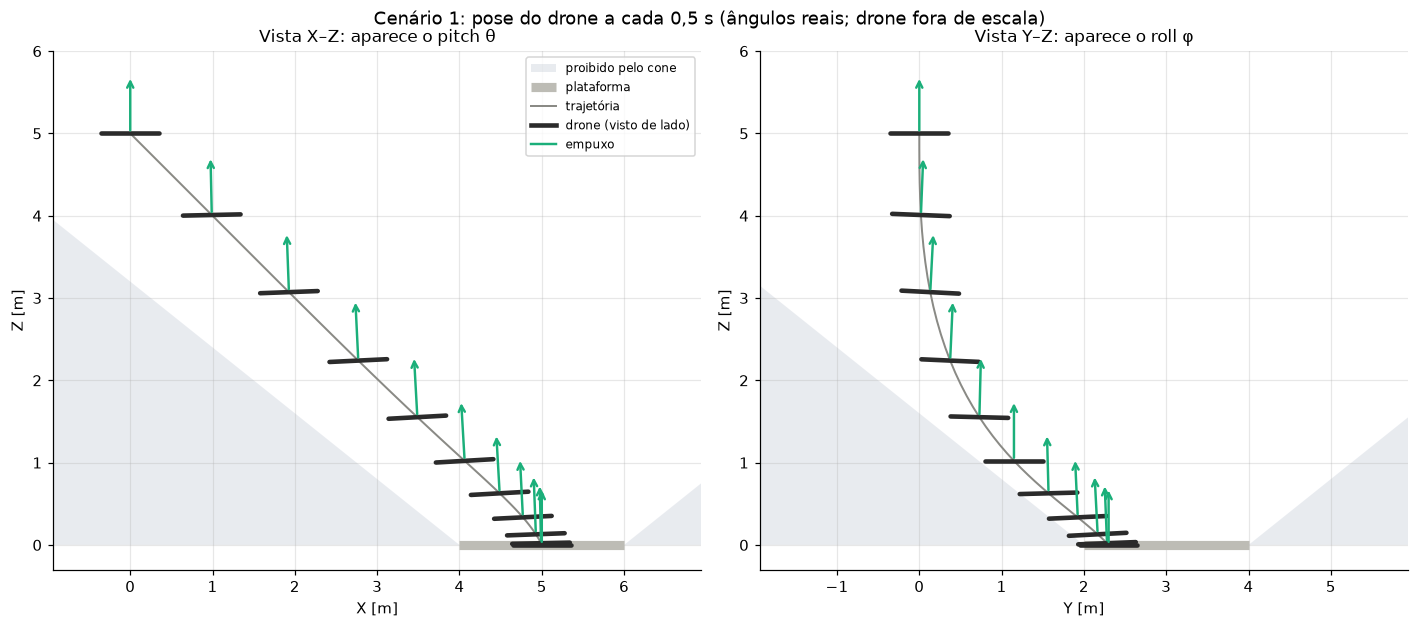

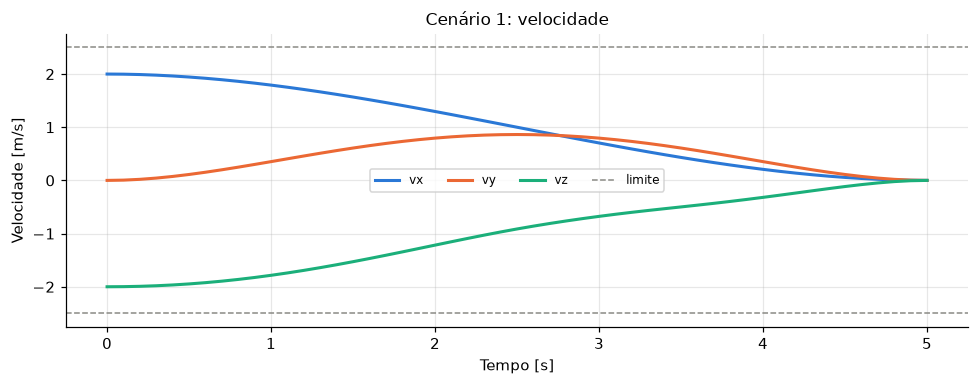

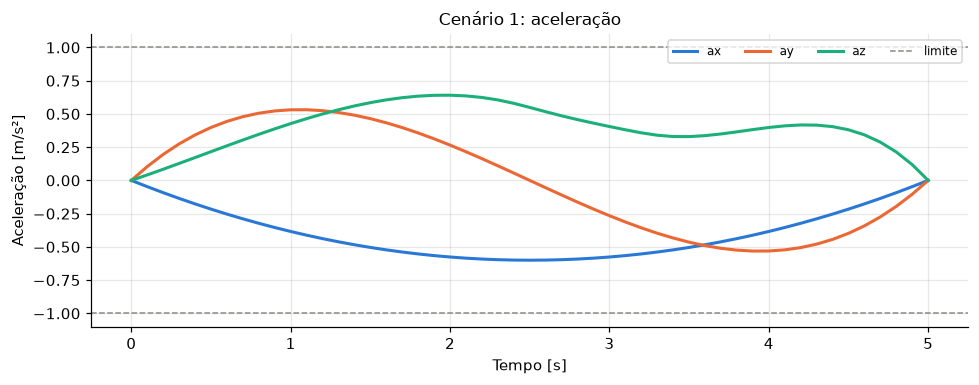

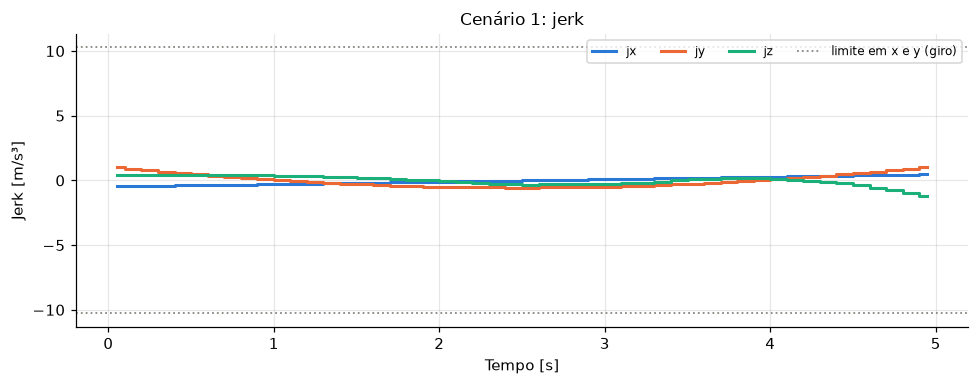

In [13]:
plotar_cenario(resultados[1])

**O que o resultado mostra.**
- Pouso suave e folgado: inclinação máxima de 3,3°, motores entre 521 e 538 rad/s (a rotação de pairado é 521). O drone usa uma pequena parte da sua capacidade.
- O pouso acontece em (5,0; 2,3), exatamente na margem do lado de onde o drone vem ($y = 2 + 0{,}3$): o ótimo encurta o caminho e não vai até o centro.
- A única restrição ativa é o **limite de descida por altura** (em 11 instantes): é ela que molda a chegada ao chão.

### Cenário 2 — Tempo de sobra

O mesmo ponto de partida, mas com $T = 15$ s, bem mais do que o necessário.

In [14]:
resultados[2] = resolver_cenario({"nome": "Cenário 2", "p0": (0, 0, 5), "v0": (2, 0, -2), "T": 15.0,
                                  "v_max": 2.5, "a_max": 1.0})
resumo(resultados[2])

Cenário 2 | status: optimal | 1775 iterações, 1.2 s
  J* = 0.667 | pouso em (5.70, 3.70)
  inclinação máxima: pitch 2.3°, roll 1.5° (limite 30°)
  empuxo: 12.9 a 13.9 N | motores: 519 a 537 rad/s | giro máximo: 2°/s
  velocidade máxima: 2.00 m/s | aceleração máxima: 0.62 m/s²
  restrições ativas (nº de instantes): {'chão': 2, 'cone': 2}


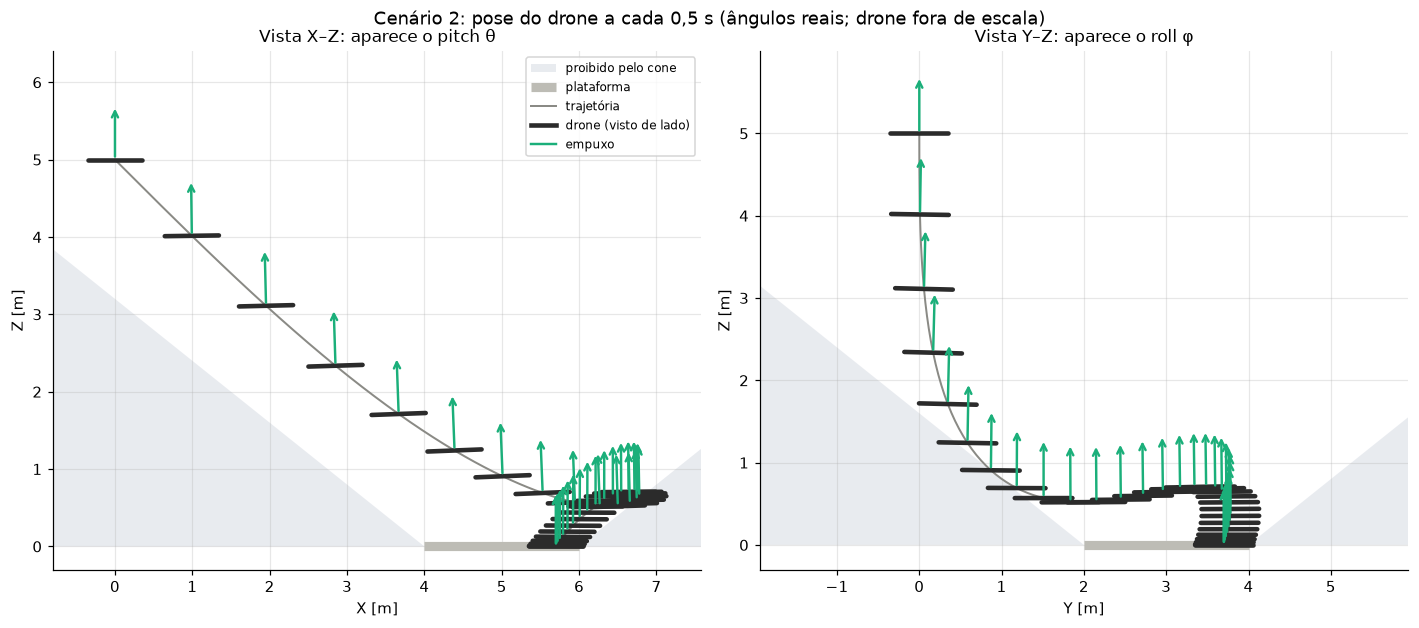

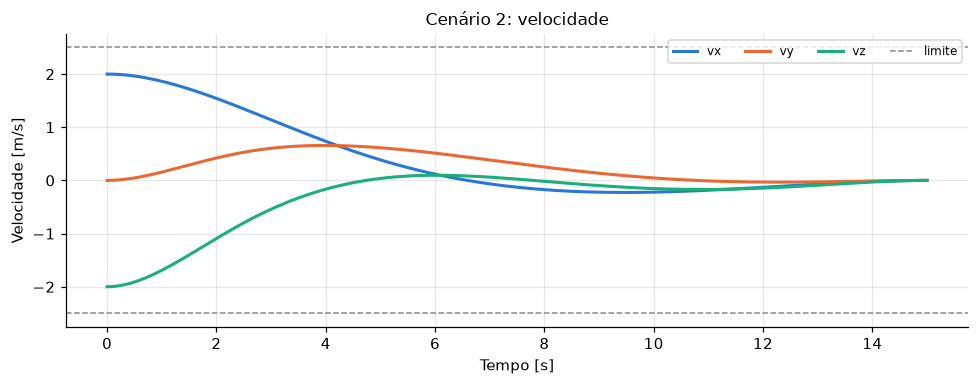

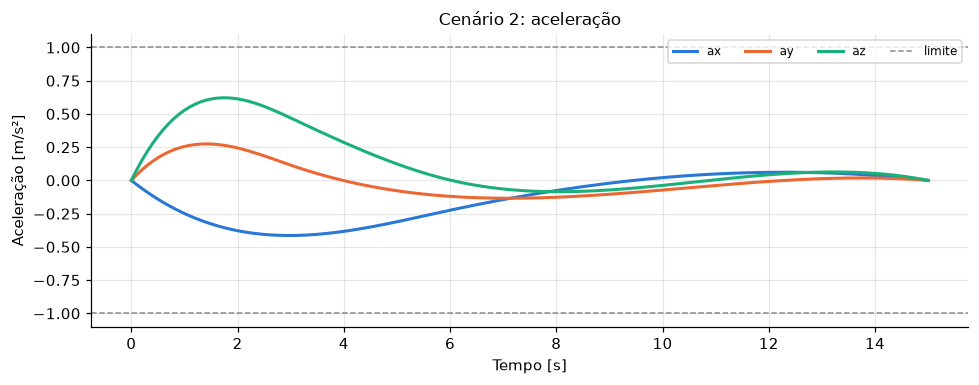

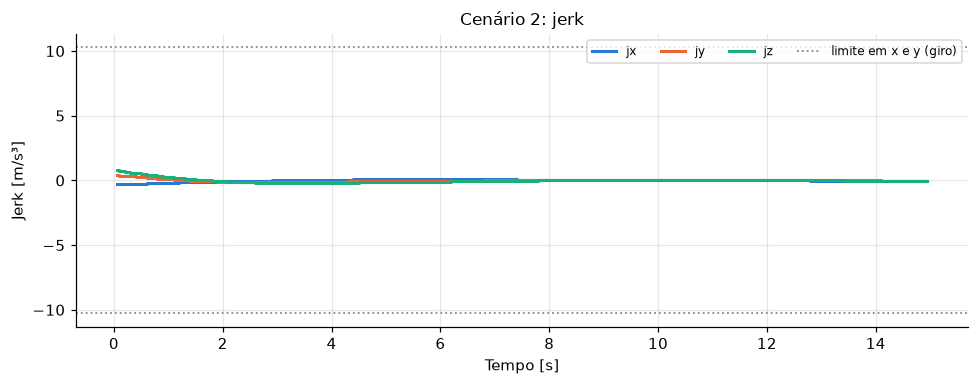

In [15]:
plotar_cenario(resultados[2])

**O que o resultado mostra.**
- Com mais tempo, $J$ cai de 2,28 para 0,67: as mudanças de aceleração podem ser mais lentas.
- Mas o drone **não vai direto**. Por volta de $t = 4$ s ele já está baixo (cerca de 0,5 m) perto da plataforma, passa da borda (até $x \approx 6{,}8$ m), contorna voando **rente ao cone** (restrição ativa) e só pousa no fim, no canto oposto (5,7; 3,7). O "chão ativo" é o drone encostando na plataforma nos últimos instantes.
- O modelo não cobra nada pelo tempo de voo: com tempo de sobra, o ótimo "passeia". Na prática, $T$ deve ser escolhido com cuidado (veja a Discussão).

### Cenário 3 — Tempo insuficiente

O mesmo ponto de partida com $T = 3{,}5$ s. Depois, o menor tempo com que o pouso ainda é possível (procurado numa grade de 0,1 s).

In [16]:
resultados["3a"] = resolver_cenario({"nome": "Cenário 3a (T = 3,5 s)", "p0": (0, 0, 5), "v0": (2, 0, -2),
                                     "T": 3.5, "v_max": 2.5, "a_max": 1.0})
resumo(resultados["3a"])

AVISO: T = 3.5 s é menor que o tempo mínimo de descida a partir de 5 m (4.00 s).
Cenário 3a (T = 3,5 s) | status: infeasible | None iterações, 0.2 s


In [17]:
# Menor T viável, numa grade de 0,1 s
for T_teste in np.round(np.arange(4.0, 5.01, 0.1), 1):
    r = resolver_cenario({"nome": f"T = {T_teste:g} s", "p0": (0, 0, 5), "v0": (2, 0, -2), "T": T_teste,
                          "v_max": 2.5, "a_max": 1.0})
    print(f"T = {T_teste:g} s: {r['status']}")
    if r["status"] == "optimal":
        r["nome"] = f"Cenário 3b (T = {T_teste:g} s)".replace(".", ",")
        resultados["3b"] = r
        break
resumo(resultados["3b"])

T = 4 s: infeasible
T = 4.1 s: infeasible
T = 4.2 s: infeasible
T = 4.3 s: infeasible
T = 4.4 s: optimal
Cenário 3b (T = 4,4 s) | status: optimal | 12775 iterações, 1.4 s
  J* = 20.374 | pouso em (4.40, 2.30)
  inclinação máxima: pitch 3.8°, roll 3.9° (limite 30°)
  empuxo: 12.2 a 14.4 N | motores: 505 a 547 rad/s | giro máximo: 9°/s
  velocidade máxima: 2.23 m/s | aceleração máxima: 1.00 m/s²
  restrições ativas (nº de instantes): {'descida por altura': 25, 'aceleração máxima': 5}


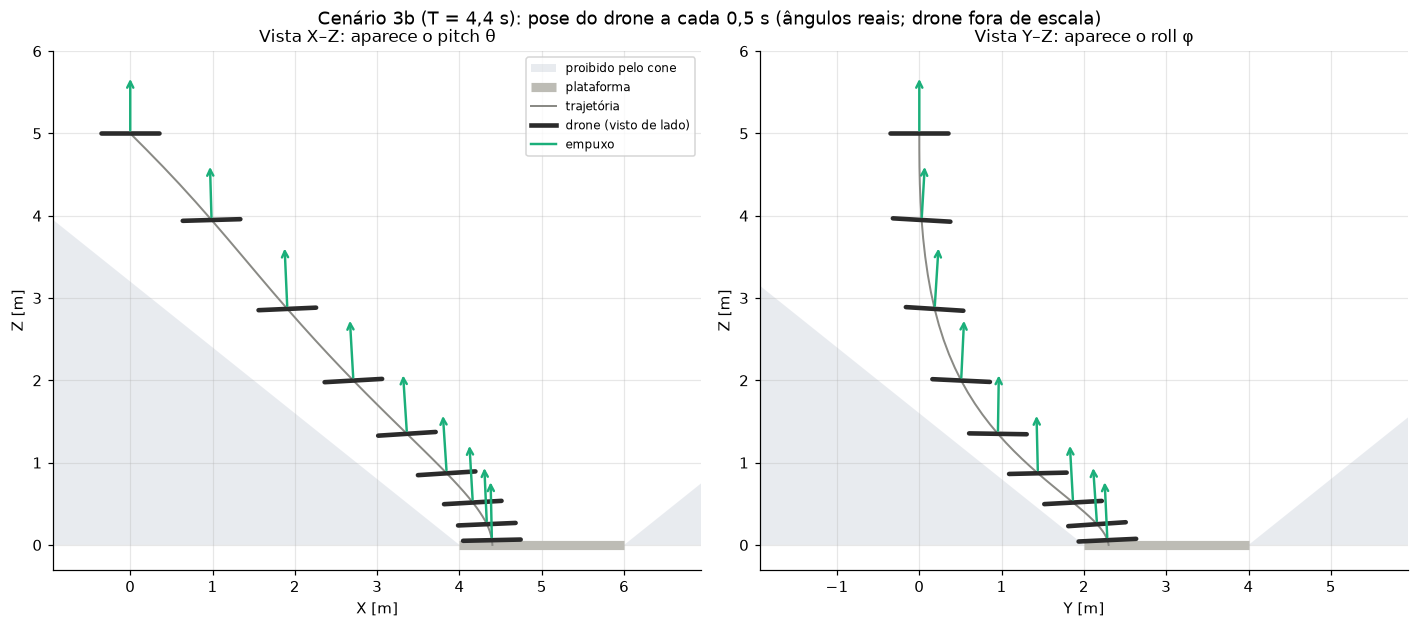

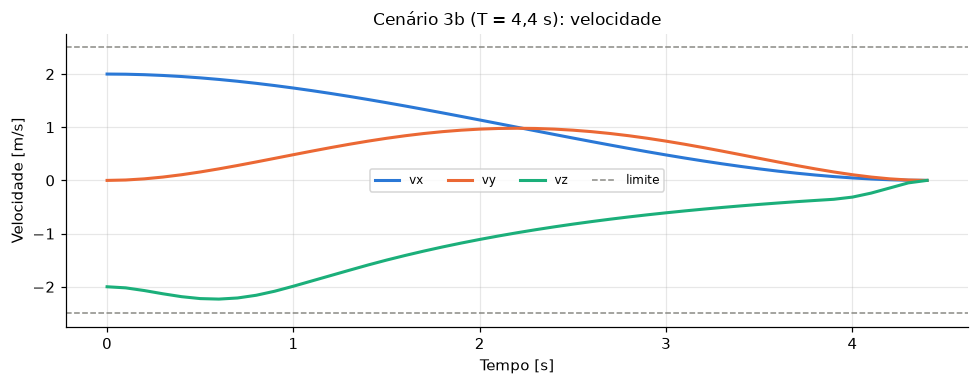

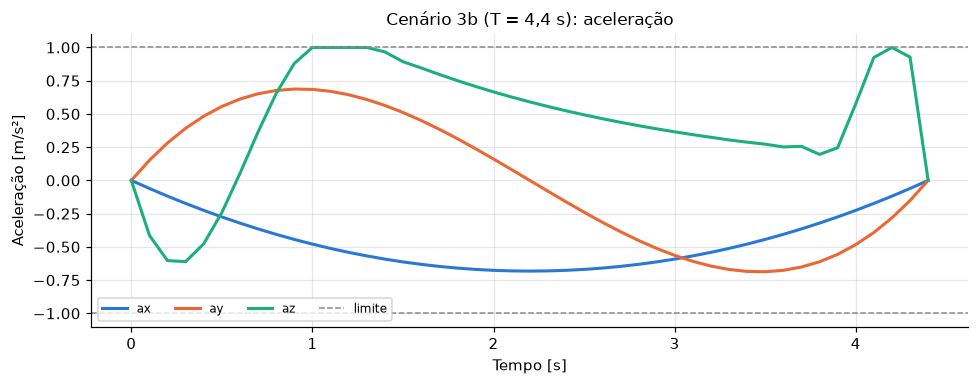

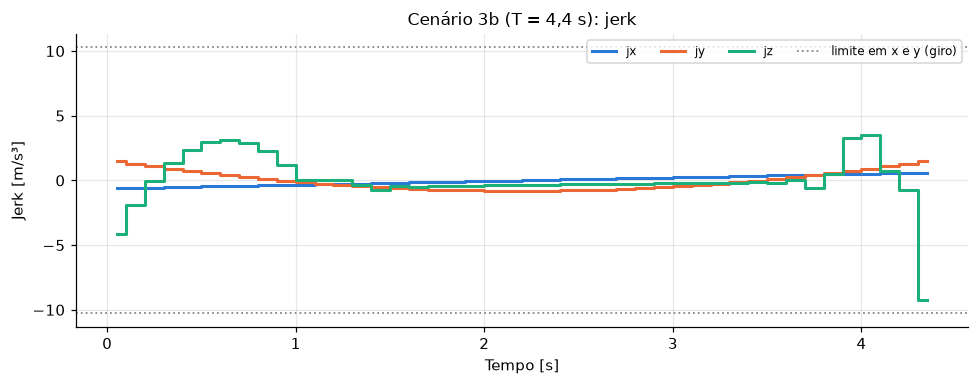

In [18]:
plotar_cenario(resultados["3b"])

**O que o resultado mostra.**
- Com $T = 3{,}5$ s o problema é **inviável**: o OSQP devolve `infeasible`, ou seja, não existe nenhuma trajetória que respeite todas as restrições. O aviso já indicava a causa: com o limite de descida, descer de 5 m leva pelo menos 4,0 s.
- O menor tempo viável é $T = 4{,}4$ s. O limite de aceleração de 1 m/s² também pesa: ele fica ativo junto com o limite de descida.
- Nesse limite, $J = 20{,}4$, cerca de **9 vezes** o $J$ do pouso com 5 s. Chegar no limite do possível custa muito em suavidade.

### Cenário 4 — Chegada rápida

O drone vem de longe e rápido: está em $(-6, 3, 9)$ m, voando a 8 m/s em direção à plataforma. Para isso ser possível, os limites operacionais são relaxados ($v_{\max} = 12$ m/s, sem $a_{\max}$): só os limites físicos do drone continuam valendo. Tempo de pouso: $T = 6$ s.

In [19]:
resultados[4] = resolver_cenario({"nome": "Cenário 4", "p0": (-6, 3, 9), "v0": (8, 0, 0), "T": 6.0,
                                  "v_max": 12.0, "a_max": None})
resumo(resultados[4])

Cenário 4 | status: optimal | 7600 iterações, 1.1 s
  J* = 94.677 | pouso em (5.70, 3.00)
  inclinação máxima: pitch 23.1°, roll 0.0° (limite 30°)
  empuxo: 8.4 a 15.9 N | motores: 418 a 576 rad/s | giro máximo: 38°/s
  velocidade máxima: 8.00 m/s | aceleração máxima: 3.86 m/s²
  restrições ativas (nº de instantes): {'descida por altura': 36}


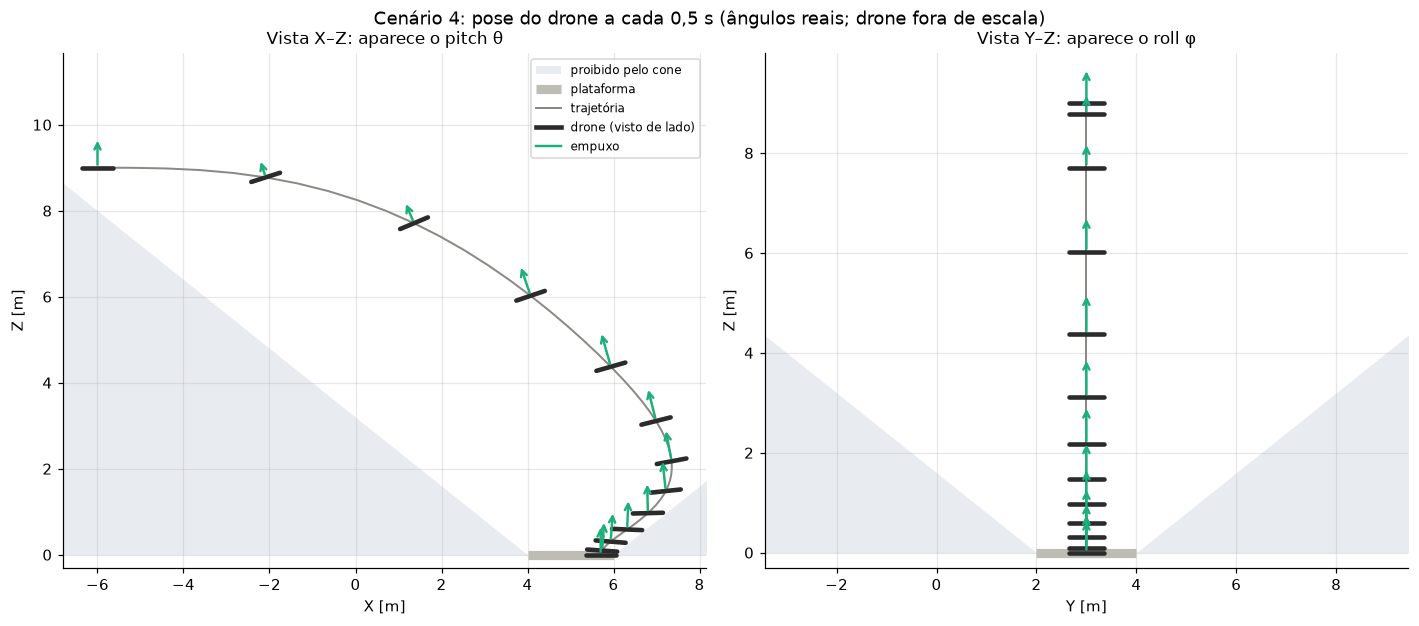

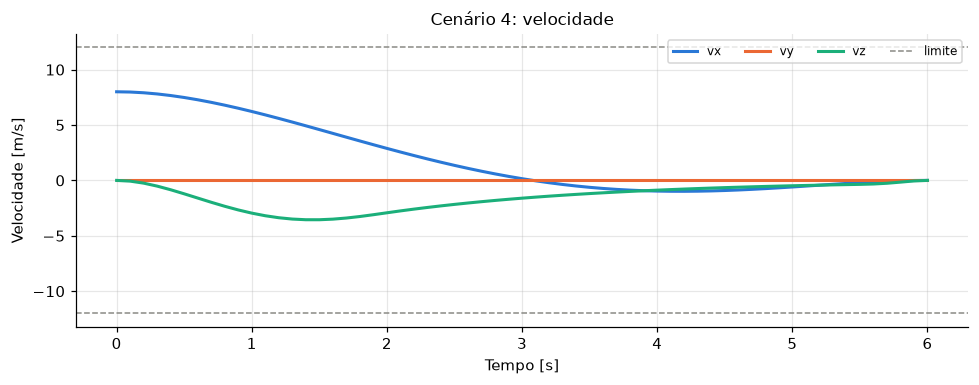

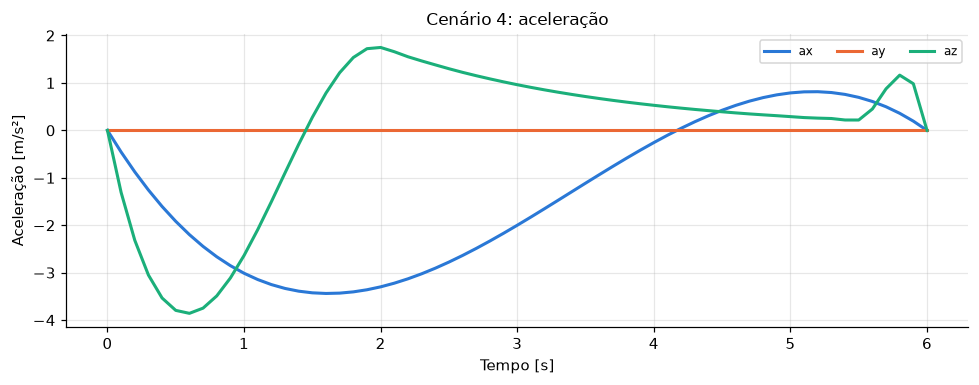

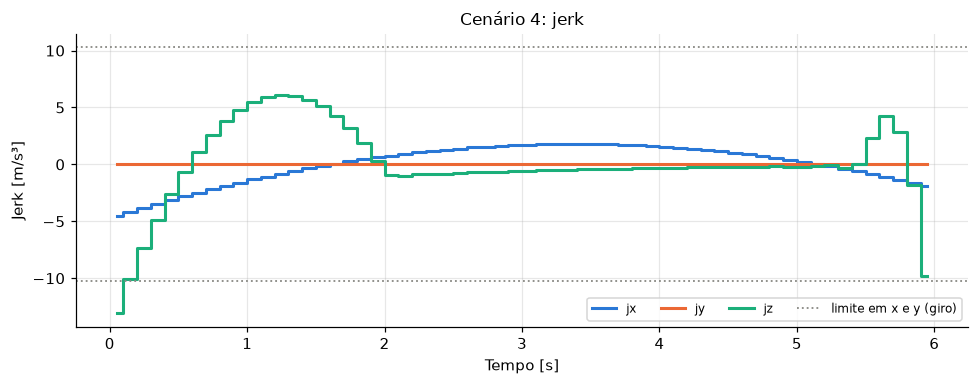

In [20]:
plotar_cenario(resultados[4])

#### Ângulos do drone e o limite de inclinação

Pitch e roll ao longo do pouso, cada um no seu gráfico, com o limite de 30° tracejado e o valor máximo atingido.

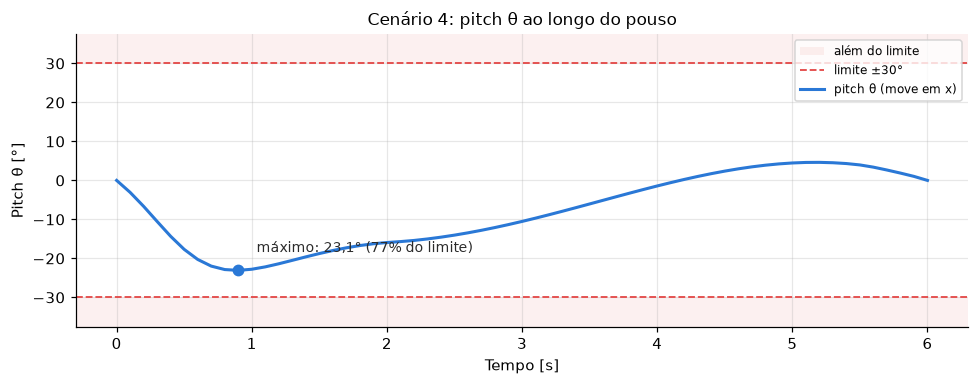

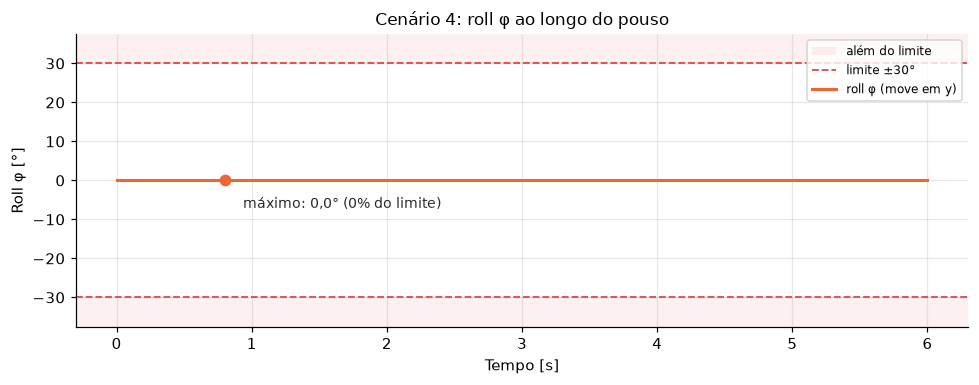

In [21]:
from graficos_resultados import plotar_angulos

plotar_angulos(resultados[4])

**O que o resultado mostra.**
- Para frear de 8 m/s, o drone inclina para trás (pitch negativo): o pitch chega a 23,1°, ou seja, 77% do limite de 30°. Como ele já vem alinhado com a plataforma em $y$, o roll fica em zero.
- Nenhum limite físico do drone fica ativo; só o limite de descida. Mesmo assim, $J = 94{,}7$, cerca de 40 vezes o do pouso típico, pelo esforço de frear.
- O empuxo varia de 8,4 a 15,9 N (motores entre 418 e 576 rad/s), bem mais que no pouso típico.
- O drone passa da plataforma (até $x \approx 7{,}4$ m) e volta para pousar em (5,7; 3,0).

# 4. Discussão

## 4.1 Limitações do modelo

- **Restrições verificadas só nos instantes $t_k$.** Entre dois instantes a trajetória é conhecida exatamente (um polinômio cúbico), mas os limites (cone, ângulos, velocidade) só são impostos nos pontos amostrados. Com $\Delta t = 0{,}1$ s, a violação entre amostras é pequena, mas não é zero. Diminuir $\Delta t$ reduz essa violação, ao custo de mais variáveis.
- **Modelo físico simplificado.** O yaw é travado, os motores respondem instantaneamente e não há vento nem arrasto. Também não modelamos a diferença de rotação entre os motores que gera os torques: usamos só a rotação média. O limite de velocidade continua sendo uma escolha operacional, porque depende do arrasto, que não está no modelo.
- **Limites físicos aproximados.** Para manter o problema linear, três limites foram escritos de forma **conservadora** (pitch, empuxo mínimo e máximo): o modelo pode rejeitar manobras que o drone conseguiria fazer. O limite de **giro** foi **linearizado** supondo $F/m \approx g$, e isso tem uma consequência: quando o empuxo fica bem abaixo do peso, o giro real é maior que o estimado. Em testes adicionais, com a partida do cenário 4 e $T = 5{,}5$ s, o pitch encostou em 30° e o empuxo caiu a 2,9 N; o giro real chegou a 116°/s, quase o dobro do limite de 60°/s.
- **Tempo de pouso fixo.** $T$ é escolhido antes de resolver, e o ótimo depende muito dele. Pouco tempo deixa o problema inviável ou muito caro (cenário 3); tempo demais faz o drone "passear" rente ao chão (cenário 2), porque o objetivo não cobra nada pelo tempo de voo.
- **Planejamento em malha aberta.** O QP calcula a trajetória uma vez, a partir do estado inicial. Com vento ou erros de controle, o drone se afasta do plano, e seria preciso replanejar (seção 4.3).

## 4.2 Casos especiais observados

- **Inviabilidade.** Quando nenhuma trajetória respeita todas as regras, o solver não devolve uma "solução ruim": ele **prova** que não há solução (status `infeasible`, cenário 3a). As duas causas mais comuns foram previstas pelo próprio modelo: $T$ menor que o tempo mínimo de descida e ponto de partida fora do cone. Por isso `resolver_cenario` avisa antes de resolver.
- **O pouso vai para a borda da área permitida.** O ótimo escolhe o ponto de pouso que encurta o caminho, e não o centro: no cenário 1, o drone pousa em $y = 2{,}3$, exatamente na margem de segurança. Sem a margem, ele pousaria na borda da plataforma.
- **Folga do drone.** Nos pousos suaves, nenhum limite físico fica ativo: os motores giram perto da rotação de pairado (cerca de 520 rad/s, de um máximo de 907). As restrições que moldam a trajetória são as de segurança (limite de descida, cone), não as do drone. Mesmo na chegada rápida do cenário 4, o pitch chegou a 77% do limite.
- **Preço da pressa.** O custo cresce muito perto do limite do possível: o $J$ do menor tempo viável (cenário 3b, $T = 4{,}4$ s) é cerca de 9 vezes o do pouso com 5 s.
- **Comportamento do solver.** Para resolver todos os cenários com o OSQP foi preciso usar tolerância $10^{-4}$ com polimento (seção 3.1): com tolerâncias mais apertadas, os cenários próximos dos limites não convergiam. Em testes com manobras mais agressivas que as apresentadas aqui, o OSQP ficou lento e, em um caso, chegou a declarar inviável um problema que tem solução (confirmado com outro solver). É uma limitação conhecida de métodos de primeira ordem como o ADMM: são rápidos e simples, mas sensíveis a problemas mal condicionados.

## 4.3 Generalizações e variações

- **Plataforma em movimento** (tema de Lo et al., 2024): com a trajetória da plataforma conhecida, basta trocar as condições finais pela posição e velocidade dela no instante $T$; o problema **continua QP**.
- **Tempo de pouso livre:** minimizar $J(T) + \rho\,T$, em que $\rho$ é o "preço" de cada segundo de voo, resolvendo um QP para cada $T$.
- **Restrições exatas:** empuxo máximo como bola, cone circular e limites no módulo da velocidade viram restrições de cone de segunda ordem (SOCP): deixa de ser QP, mas continua **convexo**.
- **Replanejamento em tempo real (MPC):** resolver o QP de novo a cada fração de segundo, a partir do estado medido, torna o pouso robusto a vento e erros.

# 5. Referências

- Açıkmeşe, B.; Ploen, S. R. (2007). Convex programming approach to powered descent guidance for Mars landing. *Journal of Guidance, Control, and Dynamics*, 30(5), 1353–1366.
- Blackmore, L. (2016). Autonomous precision landing of space rockets. *The Bridge* (National Academy of Engineering), 46(4), 15–20.
- Bowerfind, S. R.; Kirchner, M. R.; Hewer, G. A.; Robinson, D. R.; Chen, P.; Farahmandi, A.; Estabridis, K. (2025). A model-free data-driven algorithm for continuous-time control. arXiv:2501.17400. https://arxiv.org/abs/2501.17400
- Flash, T.; Hogan, N. (1985). The coordination of arm movements: an experimentally confirmed mathematical model. *Journal of Neuroscience*, 5(7), 1688–1703.
- Hogan, N. (1984). An organizing principle for a class of voluntary movements. *Journal of Neuroscience*, 4(11), 2745–2754.
- Lo, L.-Y.; Li, B.; Wen, C.-Y.; Chang, C.-W. (2024). Towards non-robocentric dynamic landing of quadrotor UAVs. arXiv:2401.11445. https://arxiv.org/abs/2401.11445
- Mellinger, D.; Kumar, V. (2011). Minimum snap trajectory generation and control for quadrotors. *IEEE International Conference on Robotics and Automation (ICRA)*, 2520–2525. DOI: 10.1109/ICRA.2011.5980409.
- Stellato, B.; Banjac, G.; Goulart, P.; Bemporad, A.; Boyd, S. (2020). OSQP: an operator splitting solver for quadratic programs. *Mathematical Programming Computation*, 12(4), 637–672.
- T-Motor (s.d.). *AIR2216 II KV920: especificações e dados de teste com hélice T1045 (16 V)*. Datasheet do conjunto AIR Gear 450 II. Disponível em: https://cdn.robotshop.com/media/T/Tmo/RB-Tmo-266/pdf/ligpower_airgear_450ii_combo_set_multi_rotor_uav_p_datasheet.pdf. Acesso em: 17 nov. 2026.